# 2장 1강: 시계열 데이터의 이해와 정상성 진단

## 실습 목표

이번 실습에서는 **Bike Sharing Demand** 데이터를 이용해 시간에 따른 자전거 대여량 변화를 확인합니다.

- 시계열 데이터에서 **시간 순서가 중요한 이유**를 확인합니다.
- 선 그래프와 시계열 분해를 이용해 **Trend / Seasonality / Residual**을 확인합니다.
- 이동평균을 이용해 데이터의 평균적인 수준 변화를 살펴봅니다.
- **ADF Test**를 이용해 정상성을 진단합니다.
- 정상성을 만족하지 않는 경우 **1차 차분**을 적용하고 ADF Test를 다시 수행합니다.

> 이 실습에서는 교안에서 다룬 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- statsmodels
- 데이터: `Bike_Sharing_Demand.csv`

### 주요 컬럼

| 컬럼 | 의미 |
|---|---|
| `datetime` | 자전거 대여 기록 시각 |
| `casual` | 비등록 사용자의 대여 수 |
| `registered` | 등록 사용자의 대여 수 |
| `count` | 전체 자전거 대여 수 |

`count`는 `casual + registered`로 구성된 전체 대여량입니다.

## 실습 준비

먼저 데이터를 불러온 뒤 다음 내용을 확인합니다.

1. 데이터 크기와 상위 행
2. 주요 컬럼의 자료형
3. 결측치
4. `datetime`을 날짜/시간 자료형으로 변환
5. 시간 순서대로 정렬
6. 일별·월별 대여량 데이터 준비

> 일별·월별 집계 코드는 이후 시계열 실습을 위한 **준비 코드**로 제공됩니다.

**데이터 해석 주의:** 이 CSV에는 매월 1~19일 관측만 있습니다. 일별 행 사이의 간격이 일정하지 않으며, 7개 관측 이동평균은 항상 연속 7일 평균은 아닙니다. 월별 합계는 관측된 날짜의 합계입니다. period=12 분해는 24개월(2주기)뿐이라 계절성의 안정성을 충분히 입증하지 못합니다.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

bike = pd.read_csv("Bike_Sharing_Demand.csv")

print("데이터 크기:", bike.shape)
display(bike.head())

print("\n[자료형]")
display(bike[["datetime", "casual", "registered", "count"]].dtypes.to_frame("dtype"))

print("\n[결측치]")
display(bike[["datetime", "casual", "registered", "count"]].isna().sum().to_frame("missing"))

데이터 크기: (10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1



[자료형]


,dtype
datetime,str
casual,int64
registered,int64
count,int64



[결측치]


,missing
datetime,0
casual,0
registered,0
count,0


In [2]:
# datetime 변환 및 시간 순서 정렬
bike["datetime"] = pd.to_datetime(bike["datetime"])
bike = bike.sort_values("datetime").reset_index(drop=True)

print("최초 시각:", bike["datetime"].min())
print("마지막 시각:", bike["datetime"].max())
display(bike.head())

최초 시각: 2011-01-01 00:00:00
마지막 시각: 2012-12-19 23:00:00


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [3]:
# 일별 시계열 준비
bike["date"] = bike["datetime"].dt.date

daily = (bike.groupby("date", as_index=False)[["count", "casual", "registered"]].sum())

daily["date"] = pd.to_datetime(daily["date"])

# 월별 시계열 준비
bike["month"] = bike["datetime"].dt.to_period("M").astype(str)

monthly = (bike.groupby("month", as_index=False)["count"].sum())

monthly["month"] = pd.to_datetime(monthly["month"])

print("[일별 데이터]")
display(daily.head())

print("\n[월별 데이터]")
display(monthly.head())

[일별 데이터]


,date,count,casual,registered
0,2011-01-01,985,331,654
1,2011-01-02,801,131,670
2,2011-01-03,1349,120,1229
3,2011-01-04,1562,108,1454
4,2011-01-05,1600,82,1518



[월별 데이터]


,month,count
0,2011-01-01,23552
1,2011-02-01,32844
2,2011-03-01,38735
3,2011-04-01,50517
4,2011-05-01,79713


In [4]:
min_date = bike['date'].min()
max_date = bike['date'].max()
all_hour = pd.date_range(start=min_date, end=max_date, freq='d')
missing_hours = all_hour.difference(bike['date'])

print("전체", len(all_hour))
print("누락", len(missing_hours))
print(missing_hours)

전체 719
누락 263
DatetimeIndex(['2011-01-20', '2011-01-21', '2011-01-22', '2011-01-23',
               '2011-01-24', '2011-01-25', '2011-01-26', '2011-01-27',
               '2011-01-28', '2011-01-29',
               ...
               '2012-11-21', '2012-11-22', '2012-11-23', '2012-11-24',
               '2012-11-25', '2012-11-26', '2012-11-27', '2012-11-28',
               '2012-11-29', '2012-11-30'],
              dtype='datetime64[s]', length=263, freq=None)


C:\Users\tae37\AppData\Local\Temp\ipykernel_25800\3013446654.py:3: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  all_hour = pd.date_range(start=min_date, end=max_date, freq='d')


---

# 필수 1. 시간 흐름과 시계열 패턴 확인

## 배경

시계열 데이터는 값 자체뿐만 아니라 **언제 관측되었는지와 어떤 순서로 나타났는지**가 중요합니다.

Bike Sharing Demand 데이터의 전체 대여량 `count`를 시간 순서대로 확인하고, 월별 대여량을 **Trend / Seasonality / Residual**로 나누어 살펴봅니다.

## 문제 1. 일별 대여량을 시간 순서대로 확인하세요.

### 요구사항

1. `daily["date"]`를 x축, `daily["count"]`를 y축으로 선 그래프를 그립니다.
2. 그래프 제목을 `Daily Bike Rentals`로 설정합니다.
3. 시간의 흐름에 따라 대여량의 전반적인 수준이 어떻게 변화하는지 설명합니다.

### 확인 포인트

- 시계열 그래프에서는 시간 순서를 유지했는가?
- 단순히 개별 값만 보는 것이 아니라 전체적인 흐름을 확인했는가?

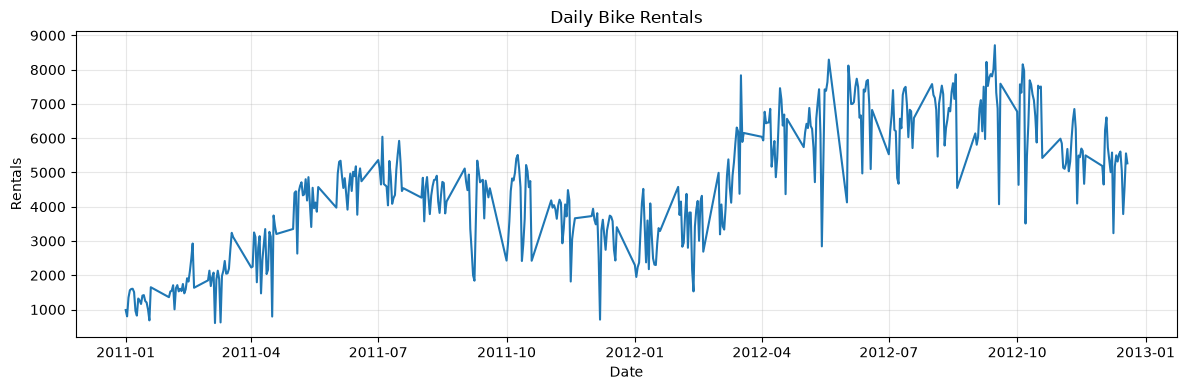

In [5]:
plt.figure(figsize=(12,4))
plt.plot(daily['date'], daily['count'])
plt.title('Daily Bike Rentals'); plt.xlabel('Date'); plt.ylabel('Rentals')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### 수준은 값이 대체로 어느 높이에서 움직이는 지
### 변동은 그 수준 주변에서 값이 얼마나 오르내리는 지

#### 시계열에서 결측과 시간 누락은 다른 개념으로 반드시 시간 누락은 체크해야 한다.
#### 해석: 관측된 일별 대여량은 2011년보다 2012년에 높은 수준을 보이며, 변동이 상승과 하락이 큰편이다.
#### 비교적 여름철에 상승하고 겨울철에 하강하는 모습을 보이지만 시간 누락이 있기 때문에 유의하여 해석 해야한다.

**답변:**  
### Q1. 왜 `daily` 데이터를 무작위로 섞지 않고 날짜 순서대로 확인해야 할까요?
#### 시계열 데이터에서는 값이 나타난 순서 자체가 정보
#### 날짜 순서가 엉망이면 어떤 값이 언제 발생했고, 나중에 발생했고, 증가나 감소 흐름을 명확하게 파악하기는 어렵다

## 문제 2. 월별 대여량을 시계열 분해하세요.

### 요구사항

1. `monthly`의 `month`를 인덱스로 설정합니다.
2. `seasonal_decompose()`를 사용합니다.
3. `model="additive"`를 사용합니다.
4. 월별 데이터의 1년 반복 주기를 확인하기 위해 `period=12`를 사용합니다.
5. 결과에서 `Observed`, `Trend`, `Seasonal`, `Residual`을 확인합니다.

### 확인 포인트

- `period=12`의 의미를 이해했는가?
- Trend / Seasonality / Residual을 구분할 수 있는가?

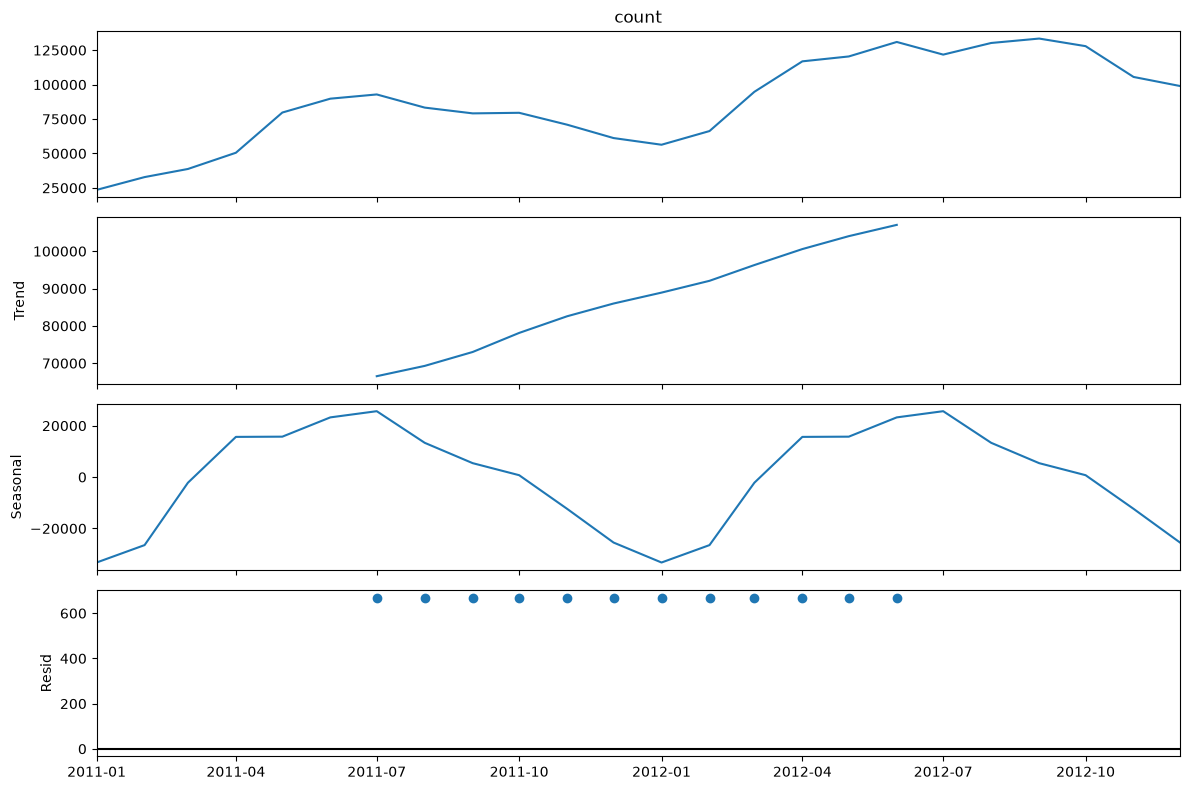

In [6]:
monthly_ts = monthly.set_index('month').asfreq('MS')
decomposition = seasonal_decompose(monthly_ts['count'], model='additive', period=12)
fig = decomposition.plot(); fig.set_size_inches(12,8); plt.tight_layout(); plt.show()

### Q2. 다음 설명을 각각 Trend / Seasonality / Residual과 연결하세요.

- 시간이 지나면서 나타나는 장기적인 증가 또는 감소
- 일정한 시간 간격을 두고 반복되는 변화
- 추세와 계절성을 제외하고 남은 변동

# 해석: 월별 관측 합계를 분해한 결과, 가운데 구간(봄, 여름)에서 상승하는 추세와 연말(가을, 겨울)에 낮아지는
# 계절 성분이 나타났고, 잔차는 거의 일정해 보이지만 시간 누락과 기간을 고려하여 계산하여야 한다.

**답변:**  
장기적인 증가·감소는 **Trend(추세)**, 일정 간격의 반복 변화는 **Seasonality(계절성)**, 두 성분을 제외한 변동은 **Residual(잔차)** 입니다.

---

# 필수 2. 정상성 진단과 1차 차분

## 배경

정상성은 시간이 지나도 시계열의 **평균적인 수준과 변동의 특성이 크게 달라지지 않는 성질**입니다.

이번 문제에서는 일별 전체 대여량 `count`의 이동평균을 확인하고, ADF Test를 이용해 정상성을 판단합니다. 정상성을 만족한다고 보기 어렵다면 1차 차분을 수행한 뒤 다시 ADF Test를 진행합니다.

## 문제 1. 이동평균으로 평균 수준의 변화를 확인하세요.

### 요구사항

1. `daily["count"]`의 최근 7개 값 이동평균을 계산하여 `rolling_mean` 컬럼에 저장합니다.
2. 원본 `count`와 `rolling_mean`을 같은 그래프에 나타냅니다.
3. 이동평균이 시간에 따라 변하는지 확인합니다.

### 확인 포인트

- `rolling(window=7).mean()`을 사용했는가?
- 이동평균이 개별 값의 작은 변동을 줄여 전체 수준을 보기 위한 방법임을 이해했는가?

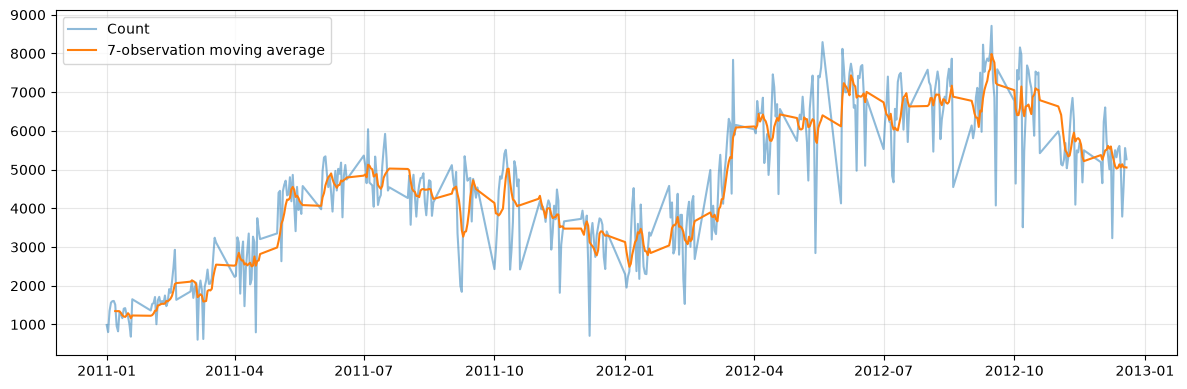

이동평균도 계절과 연도에 따라 변하므로 평균 수준이 일정하다고 보기 어렵습니다.


In [7]:
daily['rolling_mean'] = daily['count'].rolling(window=7).mean()
plt.figure(figsize=(12,4))
plt.plot(daily['date'], daily['count'], alpha=.5, label='Count')
plt.plot(daily['date'], daily['rolling_mean'], label='7-observation moving average')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print('이동평균도 계절과 연도에 따라 변하므로 평균 수준이 일정하다고 보기 어렵습니다.')

## 문제 2. 원본 일별 대여량에 ADF Test를 수행하세요.

### 요구사항

1. `adfuller()`를 이용해 `daily["count"]`를 검정합니다.
2. ADF Statistic과 p-value를 출력합니다.
3. 유의수준 0.05를 기준으로 정상성을 판단합니다.

### 판단 기준

- `p-value < 0.05` → 귀무가설 기각 → 정상성을 만족한다고 판단
- `p-value ≥ 0.05` → 귀무가설을 기각하지 못함 → 정상성을 만족한다고 보기 어려움

In [8]:
adf_original = adfuller(daily['count'])
print(f'ADF Statistic: {adf_original[0]:.6f}, p-value: {adf_original[1]:.6g}')
print('단위근 귀무가설 기각' if adf_original[1] < .05 else '단위근 귀무가설을 기각하지 못함')

ADF Statistic: -2.002469, p-value: 0.285492
단위근 귀무가설을 기각하지 못함


C:\Users\tae37\AppData\Local\Temp\ipykernel_25800\3671635262.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_original = adfuller(daily['count'])


### Q3. 원본 데이터의 p-value를 기준으로 정상성을 어떻게 판단할 수 있나요?

**답변:**  
원본 ADF 통계량은 -2.0025, p-value는 0.285492입니다. 0.05 이상이므로 단위근 귀무가설을 기각하지 못하며, 정상성을 만족한다고 보기 어렵습니다. 이는 비정상성을 확정한다는 뜻은 아닙니다.

## 문제 3. 1차 차분 후 정상성을 다시 확인하세요.

### 요구사항

1. `.diff()`를 이용해 `daily["count"]`를 1차 차분합니다.
2. 첫 번째 `NaN`은 `dropna()`로 제거합니다.
3. 차분된 값을 선 그래프로 나타냅니다.
4. 차분 데이터에 ADF Test를 다시 수행합니다.
5. 차분 전과 차분 후 p-value를 비교하여 정상성 변화를 설명합니다.

### 확인 포인트

- 차분값이 `현재 값 - 이전 값`이라는 것을 이해했는가?
- 차분 후 데이터의 의미가 **일별 대여량 → 이적 관측일 대비 대여량 변화**로 달라짐을 이해했는가?
- 차분 후 ADF Test를 다시 수행했는가?

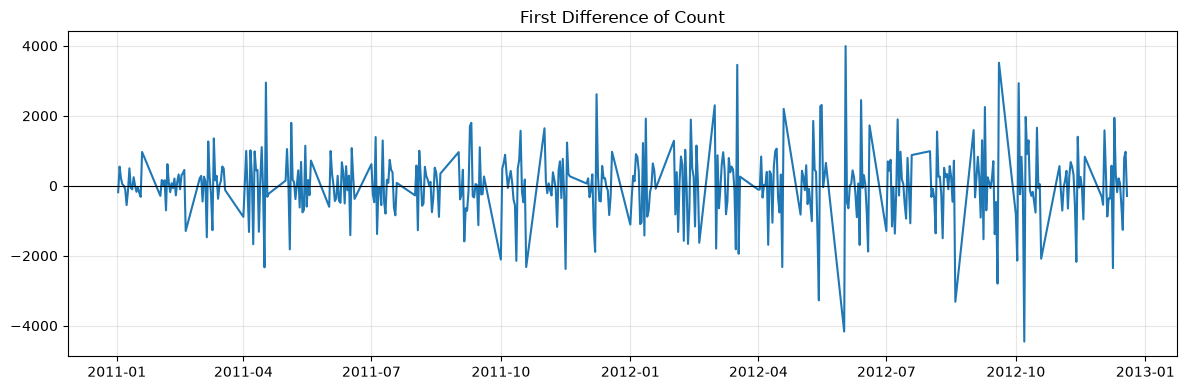

ADF Statistic: -11.751565, p-value: 1.20572e-21
차분 전 p=0.285492 → 차분 후 p=1.20572e-21


C:\Users\tae37\AppData\Local\Temp\ipykernel_25800\1738301841.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(count_diff)


In [9]:
daily['count_diff'] = daily['count'].diff()
count_diff = daily['count_diff'].dropna()
plt.figure(figsize=(12,4)); plt.plot(daily.loc[count_diff.index,'date'], count_diff)
plt.axhline(0,color='black',lw=.8); plt.title('First Difference of Count')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()
adf_diff = adfuller(count_diff)
print(f'ADF Statistic: {adf_diff[0]:.6f}, p-value: {adf_diff[1]:.6g}')
print(f'차분 전 p={adf_original[1]:.6g} → 차분 후 p={adf_diff[1]:.6g}')

### Q4. 차분 전과 차분 후 데이터의 의미는 어떻게 달라지나요?

**답변:**  
차분 전은 해당 관측일의 대여량이고, 차분 후는 현재 관측일 대여량에서 이전 관측일 대여량을 뺀 변화량입니다. 차분 후 p-value=1.20572e-21로 0.05 미만이므로 단위근 귀무가설을 기각합니다. 날짜가 빠져 있으므로 반드시 전날 대비 변화는 아닙니다.

---

# 과제 1. 등록 사용자 대여량의 정상성 진단

## 배경

필수 2에서는 전체 대여량 `count`를 이용해 정상성 진단과 차분을 수행했습니다.

이번에는 같은 과정을 **등록 사용자 대여량 `registered`**에 직접 적용합니다.

> 과제는 필수 실습에서 연습한 방법을 동일하게 적용하는 수준입니다.

## 요구사항

1. `daily["registered"]`를 날짜 순서대로 선 그래프로 나타냅니다.
2. 최근 7개 값의 이동평균을 계산하여 원본 데이터와 함께 나타냅니다.
3. 원본 `registered`에 ADF Test를 수행합니다.
4. p-value를 기준으로 정상성을 판단합니다.
5. 정상성을 만족한다고 보기 어렵다면 1차 차분합니다.
6. 1차 차분을 수행한 경우, 차분 데이터에 ADF Test를 다시 수행합니다.
7. 원본과 차분 데이터의 p-value를 근거로 정상성 판단을 설명합니다. 차분하지 않았다면 그 이유를 설명합니다.
8. 진단 결과를 근거로 원본 데이터를 사용할지, 1차 차분한 데이터를 사용할지, 추가 진단이 필요한지 선택하고 이유를 설명합니다.

### 확인 포인트

- 원본 데이터의 시간 흐름을 확인했는가?
- 이동평균으로 평균 수준의 변화를 확인했는가?
- ADF Test의 p-value를 0.05와 비교했는가?
- 필요한 경우 1차 차분 후 ADF Test를 다시 수행했는가?
- 결과를 코드 출력값을 근거로 설명했는가?
- ADF 검정 결과와 그래프를 근거로 이후 모델링 방향을 선택했는가?


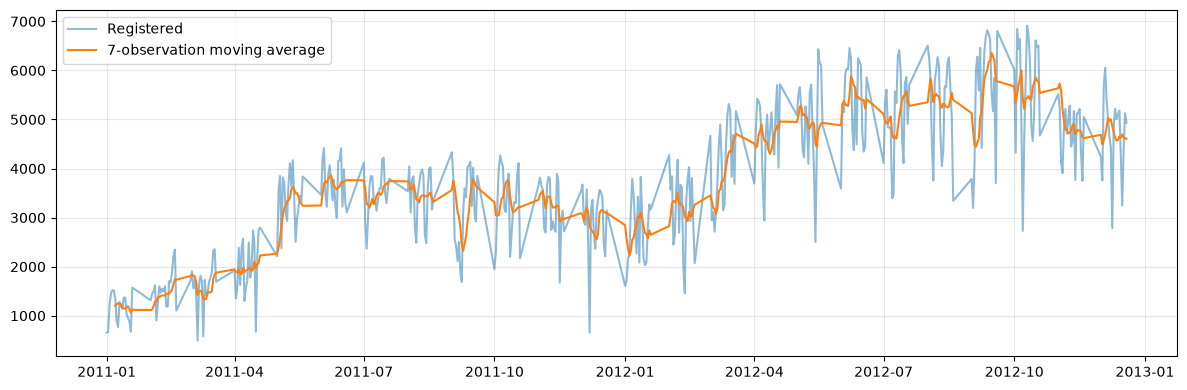

원본 ADF Statistic=-1.906962, p-value=0.328793


C:\Users\tae37\AppData\Local\Temp\ipykernel_25800\2818989863.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_registered = adfuller(daily['registered'])


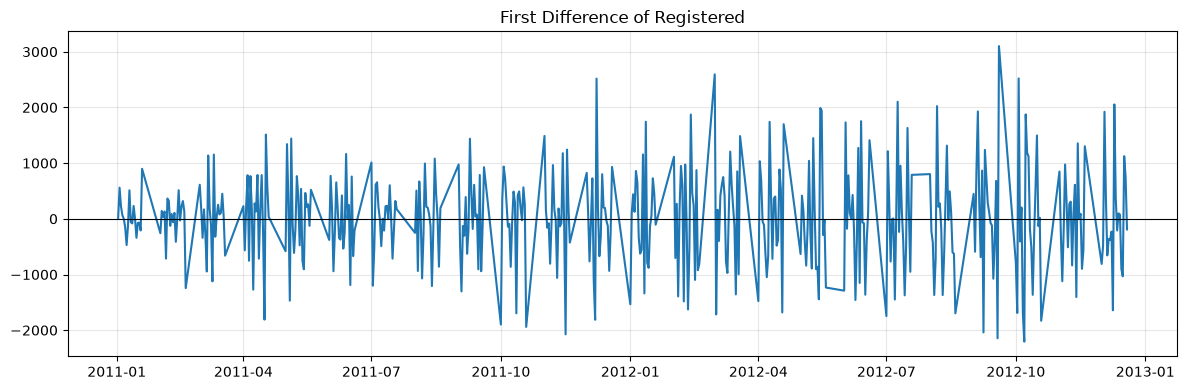

차분 ADF Statistic=-6.353678, p-value=2.57386e-08
1차 차분을 우선 검토하되 계절성과 관측 간격을 추가 진단합니다.


C:\Users\tae37\AppData\Local\Temp\ipykernel_25800\2818989863.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_registered_diff = adfuller(registered_diff)


In [10]:
daily['registered_rolling_mean'] = daily['registered'].rolling(window=7).mean()
plt.figure(figsize=(12,4))
plt.plot(daily['date'],daily['registered'],alpha=.5,label='Registered')
plt.plot(daily['date'],daily['registered_rolling_mean'],label='7-observation moving average')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
adf_registered = adfuller(daily['registered'])
print(f'원본 ADF Statistic={adf_registered[0]:.6f}, p-value={adf_registered[1]:.6g}')
adf_registered_diff = None
if adf_registered[1] >= .05:
    registered_diff = daily['registered'].diff().dropna()
    plt.figure(figsize=(12,4)); plt.plot(daily.loc[registered_diff.index,'date'],registered_diff)
    plt.axhline(0,color='black',lw=.8); plt.title('First Difference of Registered')
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
    adf_registered_diff = adfuller(registered_diff)
    print(f'차분 ADF Statistic={adf_registered_diff[0]:.6f}, p-value={adf_registered_diff[1]:.6g}')
    print('1차 차분을 우선 검토하되 계절성과 관측 간격을 추가 진단합니다.' if adf_registered_diff[1]<.05 else '추가 진단이 필요합니다.')
else:
    print('원본의 단위근 귀무가설을 기각하므로 차분하지 않습니다. 그래프와 계절성을 추가 확인합니다.')

### Q5. 원본 등록 사용자 대여량의 ADF 검정 결과를 어떻게 해석할 수 있나요? 차분했다면 차분 전후 결과를 비교하고, 차분하지 않았다면 그 이유를 설명하세요.

**답변:**
원본 ADF 통계량=-1.9070, p-value=0.328793로 귀무가설을 기각하지 못해 1차 차분했습니다. 차분 후 통계량=-6.3537, p-value=2.57386e-08로 귀무가설을 기각하여 단위근 관점의 정상성이 개선되었습니다.

### Q6. 이후 시계열 모델링에서는 원본 데이터 사용, 1차 차분 데이터 사용, 추가 진단 중 어떤 방향을 선택하겠나요? ADF 검정 결과와 그래프를 근거로 설명하세요.

**답변:**
1차 차분 사용을 우선 검토하겠습니다. 원본 이동평균은 계절·연도에 따라 달라지지만 차분값은 0 부근에서 움직이고 ADF도 귀무가설을 기각했습니다. 다만 ADF만으로 모든 정상성 조건을 입증할 수 없으므로 계절성·변동폭·날짜 누락을 추가 확인합니다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 시계열 데이터에서 시간 순서가 중요한 이유는 무엇인가요?  
-> 추세·계절성·시차 관계를 유지하기 위해서입니다.

2. Trend와 Seasonality의 차이는 무엇인가요?  
-> 추세는 장기 수준 변화, 계절성은 일정 주기의 반복 변화입니다.

3. ADF Test에서 `p-value ≥ 0.05`라면 어떻게 해석하나요?  
-> 단위근 귀무가설을 기각하지 못하므로 정상성이 충분히 뒷받침되지 않습니다.

4. 1차 차분은 어떤 값을 계산하나요?  
-> 현재 관측값 − 이전 관측값입니다.

5. 차분 후 ADF Test를 다시 수행해야 하는 이유는 무엇인가요?  
-> 차분으로 단위근 특성이 개선되었는지 확인하기 위해서입니다.